<a href="https://colab.research.google.com/github/klavarihards/Markets-Strategies/blob/main/portfolio-engine/notebooks/04_overlays_and_robustness.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Portfolio Engine, Phase 4: Overlays and Robustness

Phases 1-3 built strategic portfolios and measured their risk. This notebook asks whether three faster-moving layers on top make clients better off **after costs**, and whether the Phase 2-3 conclusions survive other reasonable settings:

| Layer | Idea | Origin in this repo |
|---|---|---|
| Volatility targeting | Cut equities when a GARCH(1,1) forecast says risk is above the client's band | the QQQ GARCH project |
| Regime filter | In a "stressed" market, switch off the tilt and hold 10% more cash; rule-based and HMM detectors | the moving-average regime project |
| Tactical tilt | Black-Litterman views from 12-month time-series momentum, at most ±5 points from the core | Black-Litterman from Phase 2 |

**The decision rules were written down and committed before any of these runs** (see `RESEARCH_LOG.md`, "Pre-registration"): an overlay is kept only if it improves risk by at least 10% for the median method at a cost of at most 0.05 Sharpe, and the recommended portfolio for each profile is chosen by a fixed rule. The hold-out stays locked.

In [1]:
# Setup: clone the repo (in Colab) and install the package, plus the libraries used for cross-checks.
import os, sys

IN_COLAB = "google.colab" in sys.modules
BRANCH = "claude/eloquent-fermat-i94z76"     # change to "main" once the branch is merged

if IN_COLAB:
    os.chdir("/content")
    if not os.path.exists("Markets-Strategies"):
        !git clone -q -b {BRANCH} https://github.com/klavarihards/Markets-Strategies.git
    else:
        !git -C Markets-Strategies fetch -q origin {BRANCH} && git -C Markets-Strategies checkout -q {BRANCH} && git -C Markets-Strategies pull -q origin {BRANCH}
    os.chdir("Markets-Strategies/portfolio-engine")
    !pip install -q -e ".[download,crosscheck]"
    sys.path.insert(0, "src")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("Working directory:", os.getcwd())

# In Colab, keep data snapshots and results on Google Drive: a Colab runtime's own files
# disappear when it restarts, and the snapshot must stay the same for every later run.
# The repo's data/snapshots and results folders become links to Drive, so nothing else changes.
USE_DRIVE = IN_COLAB
if USE_DRIVE:
    import shutil
    from google.colab import drive
    drive.mount("/content/drive")
    store = "/content/drive/MyDrive/portfolio-engine"
    for local, remote in [("data/snapshots", f"{store}/snapshots"), ("results", f"{store}/results")]:
        os.makedirs(remote, exist_ok=True)
        if not os.path.islink(local):
            if os.path.isdir(local):
                shutil.copytree(local, remote, dirs_exist_ok=True)   # keep anything already there
                shutil.rmtree(local)
            os.makedirs(os.path.dirname(local) or ".", exist_ok=True)
            os.symlink(remote, local)
    print("Snapshots and results are stored in", store)

Working directory: /home/user/Markets-Strategies/portfolio-engine


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

from portfolio_engine.config import load_config, config_hash
from portfolio_engine.data import load_market_data, resolve_snapshot
from portfolio_engine.backtest import summary_table, compliance_table, save_run, metrics
from portfolio_engine.backtest.studies import (load_credit_spread, regime_signals, run_overlay_study, overlay_effects,
                                               apply_keep_rule, select_methods, robustness_study, regime_breakdown,
                                               factor_exposures, deflated_sharpe_table, daily_regime)
from portfolio_engine.allocation.overlays import equity_index_returns

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 200)

cfg = load_config("configs/phase4_overlays.yaml")
SNAPSHOT = str(resolve_snapshot(cfg["data"]["snapshot_dir"]))
data = load_market_data(cfg, snapshot_dir=SNAPSHOT)
credit = load_credit_spread(cfg)
print("Config:", cfg["name"], "| hash:", config_hash(cfg), "| snapshot", data.snapshot_id,
      "| hold-out locked from", data.holdout_start.date())

Config: phase4_overlays | hash: 7a10877139aa | snapshot 570bdef9e8ea | hold-out locked from 2024-10-23


## Step 1: Regimes

Both detectors are run walk-forward: the flag at each month-end uses only data up to that day, and applies from the next trading day.

Share of months flagged stressed: rule 17%, HMM 23%; agreement 87%


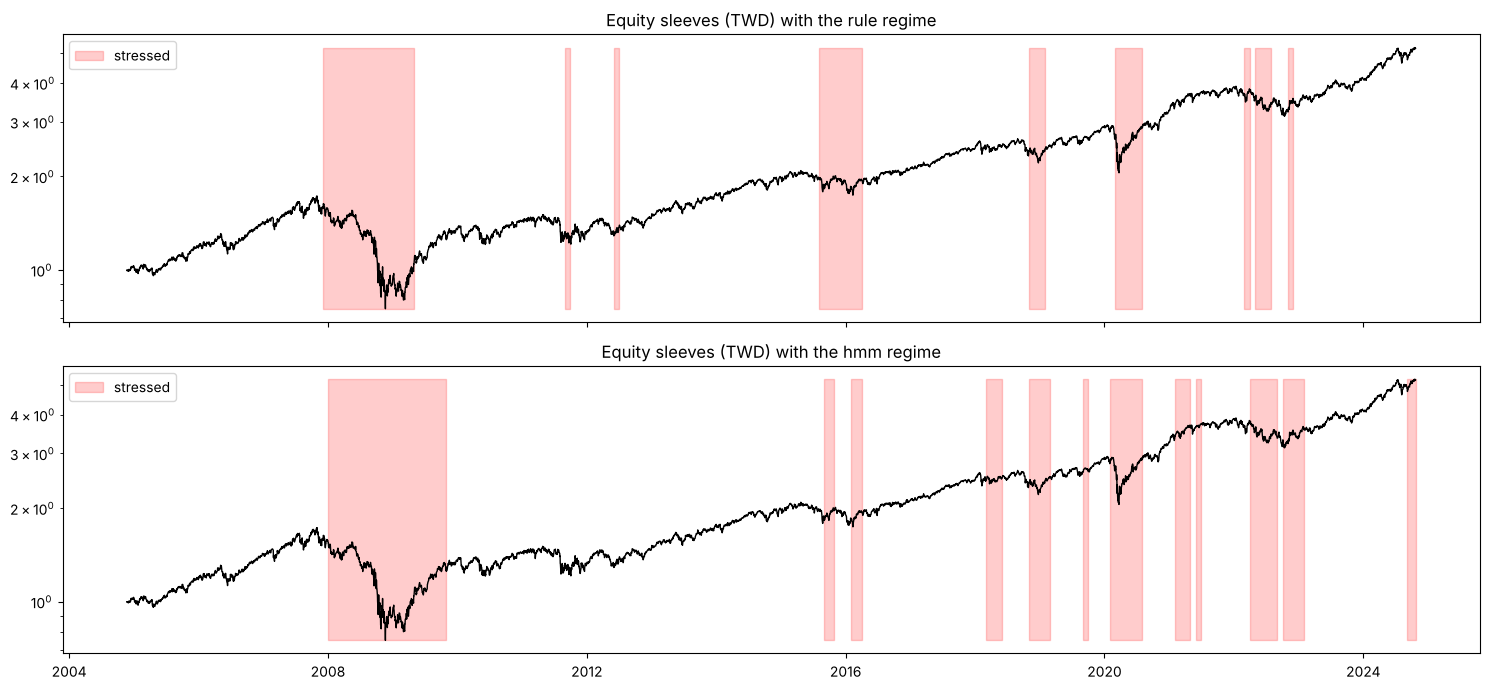

In [3]:
regimes = regime_signals(cfg, data, credit)
agree = (regimes["rule"] == regimes["hmm"]).mean()
print(f"Share of months flagged stressed: rule {regimes['rule'].mean():.0%}, HMM {regimes['hmm'].mean():.0%}; agreement {agree:.0%}")

eq = (1 + equity_index_returns(data.returns, data.asset_class)).cumprod()
fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
for ax, (name, reg) in zip(axes, regimes.items()):
    ax.plot(eq, color="black", linewidth=1)
    flag = daily_regime(reg, eq.index)
    ax.fill_between(eq.index, eq.min(), eq.max(), where=flag, color="red", alpha=0.2, label="stressed")
    ax.set_yscale("log"); ax.set_title(f"Equity sleeves (TWD) with the {name} regime"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

## Step 2: Every method under every profile, with and without each layer

108 walk-forward backtests (3 profiles x 6 methods x 6 variants, 3-year window, monthly overlay checks, all costs) plus the benchmarks. This is the slow step (about 10-15 minutes).

In [4]:
study = run_overlay_study(cfg, data, regimes)
summary = summary_table(study, data, cfg)
compliance = compliance_table(study, data, cfg)
cols = ["ann_return", "ann_vol", "sharpe", "max_drawdown", "cvar95_monthly", "turnover_per_year", "cost_drag_per_year"]
summary[cols].style.format({c: "{:.2%}" for c in cols if c != "sharpe"} | {"sharpe": "{:.2f}"})

## Step 3: Rule 1, which overlays are kept

For each profile and overlay, the change against the core portfolio for the median of the six methods. Kept only if risk (max drawdown or monthly CVaR) improves by at least 10% and Sharpe falls by no more than 0.05.

In [5]:
effects = overlay_effects(summary)
kept = apply_keep_rule(effects, cfg)
kept[["d_sharpe", "d_ann_return", "maxdd_improvement", "cvar_improvement", "risk_improvement", "d_turnover", "keep"]].style.format(
    {"d_sharpe": "{:+.3f}", "d_ann_return": "{:+.2%}", "maxdd_improvement": "{:+.0%}", "cvar_improvement": "{:+.0%}",
     "risk_improvement": "{:+.0%}", "d_turnover": "{:+.0%}"})

In [6]:
effects.style.format({"d_sharpe": "{:+.3f}", "d_ann_return": "{:+.2%}", "maxdd_improvement": "{:+.0%}",
                      "cvar_improvement": "{:+.0%}", "d_turnover": "{:+.0%}"})

## Step 4: Rule 2, the recommended portfolio for each profile

Among the portfolios (core or with kept overlays) within 0.05 Sharpe of the best for the profile: those that stayed within the client's maximum loss first, then the lowest monthly CVaR; if none stayed within the limit, the smallest maximum drawdown; ties go to the simpler method. The choice is written to `configs/final_choice.yaml`, which the hold-out evaluation and the client product use unchanged.

In [7]:
choice = select_methods(summary, compliance, kept, cfg)
frozen = {"based_on": {"config": cfg["name"], "config_hash": config_hash(cfg), "snapshot_id": data.snapshot_id,
                       "data_last": str(data.returns.index[-1].date()), "holdout_opened": False},
          "kept_overlays": {p: sorted(kept.xs(p, level="profile").query("keep").index.tolist()) for p in cfg["profiles"]},
          "portfolios": {p: {"method": r.method, "overlay": r.variant} for p, r in choice.iterrows()}}
with open("configs/final_choice.yaml", "w") as f:
    f.write("# Written by notebooks/04_overlays_and_robustness.ipynb by applying the pre-registered Rules 1 and 2\n")
    f.write("# (RESEARCH_LOG.md) to development data only. Do not edit by hand.\n")
    yaml.safe_dump(frozen, f, sort_keys=False)
display(choice.style.format({"sharpe": "{:.2f}", "max_drawdown": "{:.1%}", "cvar95_monthly": "{:.2%}"}))
print(open("configs/final_choice.yaml").read())

,method,variant,reason,sharpe,max_drawdown,cvar95_monthly,candidates
profile,,,,,,,
conservative,min_cvar,all,"within loss limit, lowest monthly CVaR",0.69,-7.4%,-1.81%,1
balanced,min_cvar,regime_hmm,"within loss limit, lowest monthly CVaR",0.60,-12.6%,-2.87%,6
growth,black_litterman,all,"within loss limit, lowest monthly CVaR",0.60,-18.2%,-4.69%,3


# Written by notebooks/04_overlays_and_robustness.ipynb by applying the pre-registered Rules 1 and 2
# (RESEARCH_LOG.md) to development data only. Do not edit by hand.
based_on:
  config: phase4_overlays
  config_hash: 7a10877139aa
  snapshot_id: 570bdef9e8ea
  data_last: '2024-10-22'
  holdout_opened: false
kept_overlays:
  conservative:
  - all
  - regime_hmm
  - regime_rule
  balanced:
  - all
  - regime_hmm
  - regime_rule
  - vol_target
  growth:
  - all
  - regime_hmm
  - regime_rule
  - vol_target
portfolios:
  conservative:
    method: min_cvar
    overlay: all
  balanced:
    method: min_cvar
    overlay: regime_hmm
  growth:
    method: black_litterman
    overlay: all



## Step 5: Robustness

The core methods for the balanced profile under other reasonable settings (rebalancing frequency, risk aversion, single-sleeve cap), and the conservative profile with a calibrated 6% volatility cap (1.645 x 6% ≈ 9.9%, inside its -10% limit). A method whose lead appears only at one setting is fragile.

In [8]:
rob, rob_runs = robustness_study(cfg, data)
pivot = rob[rob["profile"] != "benchmark"].pivot_table(index="setting", columns="method", values="sharpe")
display(pivot.style.format("{:.2f}").background_gradient(axis=1, cmap="RdYlGn"))
best = pivot.idxmax(axis=1).value_counts()
print("How often each method has the best Sharpe across settings:"); print(best.to_string())

method,black_litterman,equal_weight,hrp,mean_variance,min_cvar,risk_parity
setting,,,,,,
conservative_vol_cap=6%,0.46,0.53,0.56,0.54,0.54,0.56
max_weight=0.3,0.48,0.50,0.54,0.54,0.56,0.54
max_weight=0.4,0.48,0.50,0.53,0.45,0.55,0.54
max_weight=0.5,0.48,0.50,0.53,0.40,0.57,0.54
rebalance=annual,0.51,0.51,0.54,0.58,0.56,0.56
rebalance=monthly,0.45,0.47,0.49,0.41,0.52,0.50
rebalance=quarterly,0.48,0.50,0.53,0.45,0.55,0.54
risk_aversion=1.0,0.48,0.50,0.53,0.45,0.55,0.54
risk_aversion=10.0,0.48,0.50,0.53,0.42,0.55,0.54


How often each method has the best Sharpe across settings:
min_cvar         9
hrp              1
mean_variance    1


In [9]:
cal_cfg, cal_res = rob_runs["conservative_vol_cap=6%"]
cal_comp = compliance_table(cal_res, data, cal_cfg)
cal_comp[["realised_vol", "max_drawdown", "max_loss_limit", "max_loss_breached", "share_vol_cap_relaxed"]].style.format(
    {"realised_vol": "{:.1%}", "max_drawdown": "{:.1%}", "max_loss_limit": "{:.0%}", "share_vol_cap_relaxed": "{:.0%}"})

## Step 6: Calm vs stressed periods

The same core portfolios, split by the rule-based regime: a method that wins on average but fails in crises is unsuitable for conservative clients.

In [10]:
core_runs = {k: v for k, v in study.items() if k[1].endswith("|core") or ":" not in k[1]}
rb = regime_breakdown(core_runs, regimes["rule"], data.rf)
rb["sharpe"].unstack("regime").join(rb["ann_return"].unstack("regime"), rsuffix="_return").style.format(
    {"calm": "{:.2f}", "stressed": "{:.2f}", "calm_return": "{:.1%}", "stressed_return": "{:.1%}"})

regime,calm,stressed,calm_return,stressed_return
run,,,,
balanced:black_litterman|core,0.68,0.14,6.1%,2.9%
balanced:equal_weight|core,0.68,0.19,6.0%,3.5%
balanced:hrp|core,0.63,0.36,5.6%,5.5%
balanced:mean_variance|core,0.74,-0.09,7.3%,-0.5%
balanced:min_cvar|core,0.79,0.15,5.8%,2.6%
balanced:risk_parity|core,0.64,0.38,5.7%,5.8%
conservative:black_litterman|core,0.58,0.20,4.1%,3.0%
conservative:equal_weight|core,0.58,0.39,4.4%,5.0%
conservative:hrp|core,0.48,0.72,4.0%,8.1%


## Step 7: Factor exposures

Monthly excess returns regressed on five factors (Newey-West t-statistics): US equity, rates (intermediate Treasuries) and gold, measured in USD so they do not already contain the currency move; USD/TWD on its own (a beta of 0.5 means about half the portfolio is effectively in US dollars); and credit (tightening of the Baa-Treasury spread). This is what each portfolio is really betting on.

In [11]:
fe = factor_exposures(core_runs, data, credit)
fe.style.format("{:.2f}")

,r2,alpha_annual,beta_equity,t_equity,beta_rates,t_rates,beta_usd_twd,t_usd_twd,beta_gold,t_gold,beta_credit,t_credit
run,,,,,,,,,,,,
conservative:equal_weight|core,0.86,-0.01,0.21,12.58,0.62,17.24,0.56,15.08,0.09,9.11,0.01,4.27
conservative:mean_variance|core,0.75,-0.01,0.24,10.94,0.63,9.37,0.69,10.12,0.08,4.99,0.01,2.01
conservative:black_litterman|core,0.93,-0.01,0.26,25.07,0.46,23.47,0.57,29.23,0.05,8.93,0.01,4.69
conservative:risk_parity|core,0.89,-0.01,0.19,12.41,0.76,18.62,0.71,21.36,0.09,9.05,0.01,4.03
conservative:hrp|core,0.89,-0.01,0.19,12.34,0.74,16.47,0.69,20.84,0.09,9.84,0.01,3.01
conservative:min_cvar|core,0.89,-0.00,0.12,12.91,0.42,24.38,0.44,16.30,0.04,7.34,0.00,2.07
balanced:equal_weight|core,0.86,-0.01,0.33,17.87,0.48,12.79,0.41,10.12,0.11,8.32,0.02,4.47
balanced:mean_variance|core,0.73,-0.01,0.40,12.20,0.59,6.99,0.59,7.71,0.07,3.42,0.01,2.89
balanced:black_litterman|core,0.94,-0.01,0.39,35.01,0.57,20.46,0.71,27.77,0.06,6.69,0.01,5.24


## Step 8: How many things were tried? The deflated Sharpe ratio

Every development backtest is in `experiments/registry.csv`. The deflated Sharpe ratio asks whether each frozen portfolio's Sharpe is above the best that the same number of pure-noise trials would be expected to produce (DSR > 0.95 is the usual bar).

In [12]:
tables = {"compliance": compliance, "overlay_effects": effects, "overlay_decisions": kept, "final_choice": choice,
          "robustness": rob, "regime_breakdown": rb, "factor_exposures": fe}
run_dir = save_run(study, summary, cfg, data, tables=tables)
for label, (c, res) in rob_runs.items():
    save_run(res, summary_table(res, data, c), c, data)
chosen = [f"{p}:{r.method}|{r.variant}" for p, r in choice.iterrows()]
best_overall = summary.drop(index="benchmark", level="profile")["sharpe"].idxmax()[2]
best_name = [n for (w, n) in study if n.endswith(best_overall)][0]
dsr = deflated_sharpe_table(study, chosen + [best_name, "equal_weight", "sixty_forty"], data.rf,
                            snapshot_id=data.snapshot_id)
dsr.style.format({"sharpe_annual": "{:.2f}", "expected_max_sharpe_annual": "{:.2f}", "psr_vs_zero": "{:.2f}", "dsr": "{:.2f}"})

,sharpe_annual,expected_max_sharpe_annual,n_trials,psr_vs_zero,dsr
run,,,,,
conservative:min_cvar|all,0.69,0.22,223,1.00,0.97
balanced:min_cvar|regime_hmm,0.60,0.22,223,0.99,0.94
growth:black_litterman|all,0.60,0.22,223,0.99,0.94
equal_weight,0.52,0.22,223,0.98,0.89
sixty_forty,0.47,0.22,223,0.97,0.84


## Step 9: Reproducibility check

Re-run the regime detectors and one complete overlay backtest from scratch and compare.

In [13]:
regimes2 = regime_signals(cfg, data, credit)
for k in regimes:
    pd.testing.assert_series_equal(regimes[k], regimes2[k])
again = run_overlay_study(cfg, data, regimes2, variants=["all"], profiles=["balanced"], methods=["risk_parity"])
key = (cfg["overlays"]["window_years"], "balanced:risk_parity|all")
pd.testing.assert_series_equal(study[key].returns, again[key].returns, check_exact=True)
print("Identical: regimes and overlay backtests reproduce exactly.")

Identical: regimes and overlay backtests reproduce exactly.


## Findings

*From the run above (development data only; the full write-up of this iteration is in `RESEARCH_LOG.md`, iterations 7-8).*

- **Overlays (Rule 1):** the regime filters were kept for every profile (median method: max drawdown or CVaR 14-25% better, Sharpe +0.02 to +0.05); volatility targeting for balanced and growth (+21% and +36% risk improvement); the momentum tilt for none (more turnover, no risk benefit). "All three" passed as a package although it contains the failed tilt.
- **Frozen choice (Rule 2):** conservative min-CVaR + all overlays (Sharpe 0.69, worst drawdown -7.4%); balanced min-CVaR + HMM regime filter (0.60, -12.6%); growth Black-Litterman + all overlays (0.60, -18.2%). Deflated Sharpe ratios 0.97 / 0.94 / 0.94 (equal weight 0.89, 60/40 0.84).
- **Where the overlay benefit comes from:** almost entirely 2008-09. From 2010 on, worst drawdowns and Sharpe ratios are nearly unchanged.
- **Robustness:** for balanced clients min-CVaR had the best Sharpe in 9 of 11 settings; mean-variance was the most fragile (0.40-0.58).
- **Calibration:** with a 6% volatility cap, every conservative method except min-CVaR still broke the -10% limit, so a volatility cap is the wrong tool for a drawdown limit.
- **Factors:** dollar exposure 0.23-0.71 for the profile portfolios; R² 0.73-0.94 with near-zero alpha.